# Create Figure for the beginning of paper

In [1]:
# %load_ext autoreload
%reload_ext autoreload
%autoreload 2

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.lines as lines
import matplotlib.collections as collections
import matplotlib.colors as colors
import matplotlib.cm as cm
import matplotlib.animation as animation
import matplotlib.colors as colors
import matplotlib.cm as cm
import matplotlib.animation as animation
import matplotlib.colors as colors
import matplotlib.cm as cm
%matplotlib widget

from pathlib import Path
import gtsam
S = gtsam.Symbol

import common.fgHelpers as fgtools
from multiSession.SessionManager import SessionManager




Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [3]:
# directory = Path("../results/transitionBoundaryEval/nc/wellConstrained/quad-easy_startMapping/DISTANCE")
directory = Path("../results/twoStepEval2/nc/wellConstrained/post/park__cloister__quad-hard__quad-medium__quad-easy/TWO_OPTION")
# directory = Path("../results/relCovRerun/nc/WellConstrained/post/park__cloister__quad-hard__quad-medium__quad-easy/RELATIVE_COVARIANCE")
session = SessionManager(directory)
# session.LoadPriorGraphAndValues()
graph = session.graph
values = session.values

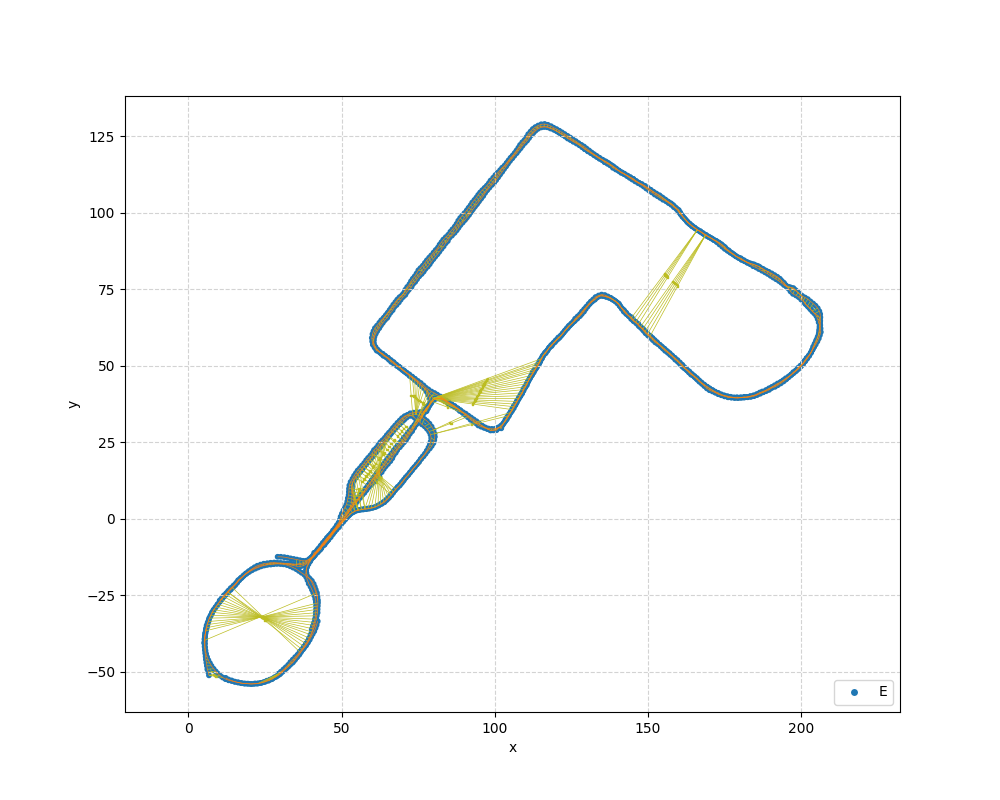

In [5]:
tmpGraph, tmpValues = fgtools.createSubGraph(graph, values, session.sessionKeys[list(session.sessionKeys.keys())[-1]])
ax2 = fgtools.plot_graph(tmpGraph, tmpValues, addKeyLabels=False, changeColorBySymbols=True)


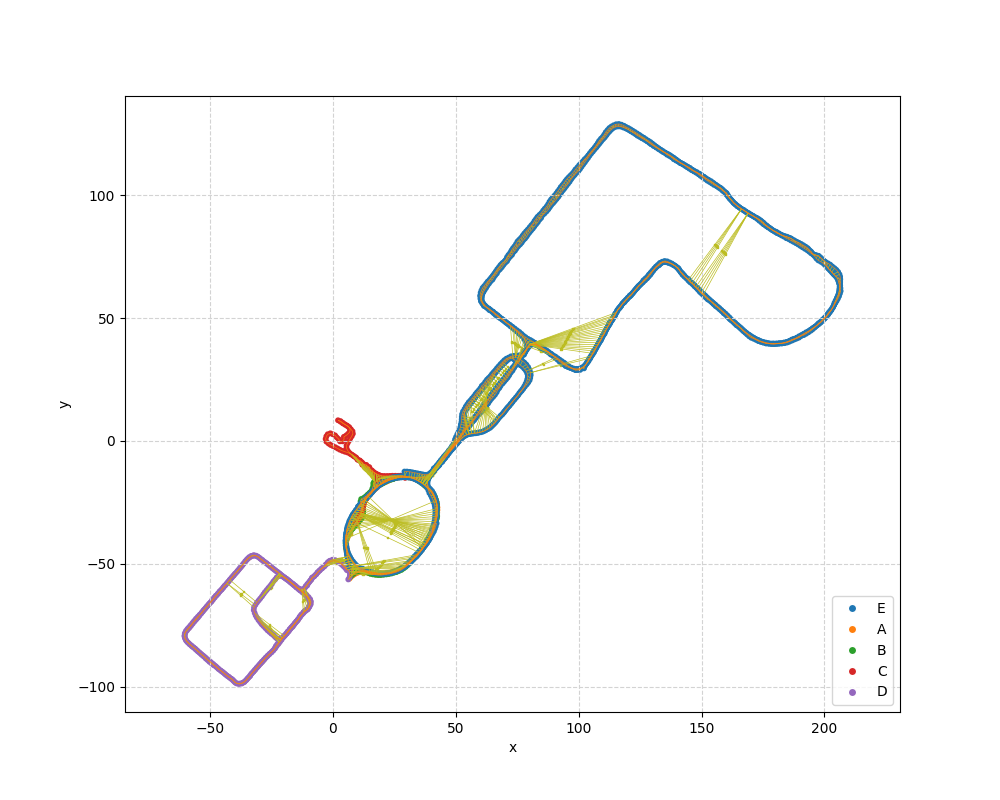

In [7]:
ax = fgtools.plot_graph(graph, values, addKeyLabels=False, changeColorBySymbols=True)

In [8]:
boundaryKeyRange = [S('c',i).key() for i in range(44,54)]

In [9]:
session.sessionKeys.keys()

dict_keys(['c', 'A', 'B', 'C', 'D', 'E'])

In [10]:
# Remove intra-session loop closures in for key in session.sessionKeys['A'] where distance > 10:
for i in range(graph.size()):
    f = graph.at(i)
    if isinstance(f, gtsam.BetweenFactorPose3):
        k1 = f.keys()[0]
        k2 = f.keys()[1]
        if (k1 in session.sessionKeys['A']) and (k2 in session.sessionKeys['A']):
            if np.linalg.norm(f.measured().translation()) > 10:
                graph.remove(i)
                print(f"Removed factor {i} between {k1} and {k2} with distance {np.linalg.norm(f.measured().translation())}")

Removed factor 76 between 4683743612465315916 and 4683743612465315865 with distance 31.35922380706246
Removed factor 78 between 4683743612465315917 and 4683743612465315866 with distance 30.689514416056564
Removed factor 80 between 4683743612465315918 and 4683743612465315867 with distance 30.325946517183986
Removed factor 82 between 4683743612465315919 and 4683743612465315867 with distance 30.21773193309658
Removed factor 84 between 4683743612465315920 and 4683743612465315867 with distance 30.071400992385293
Removed factor 86 between 4683743612465315921 and 4683743612465315867 with distance 29.888552301451814
Removed factor 88 between 4683743612465315922 and 4683743612465315867 with distance 29.72154569026858
Removed factor 90 between 4683743612465315923 and 4683743612465315867 with distance 29.555184363102725
Removed factor 92 between 4683743612465315924 and 4683743612465315866 with distance 29.342419708835425
Removed factor 94 between 4683743612465315925 and 4683743612465315866 with d

<Axes: xlabel='x', ylabel='y'>

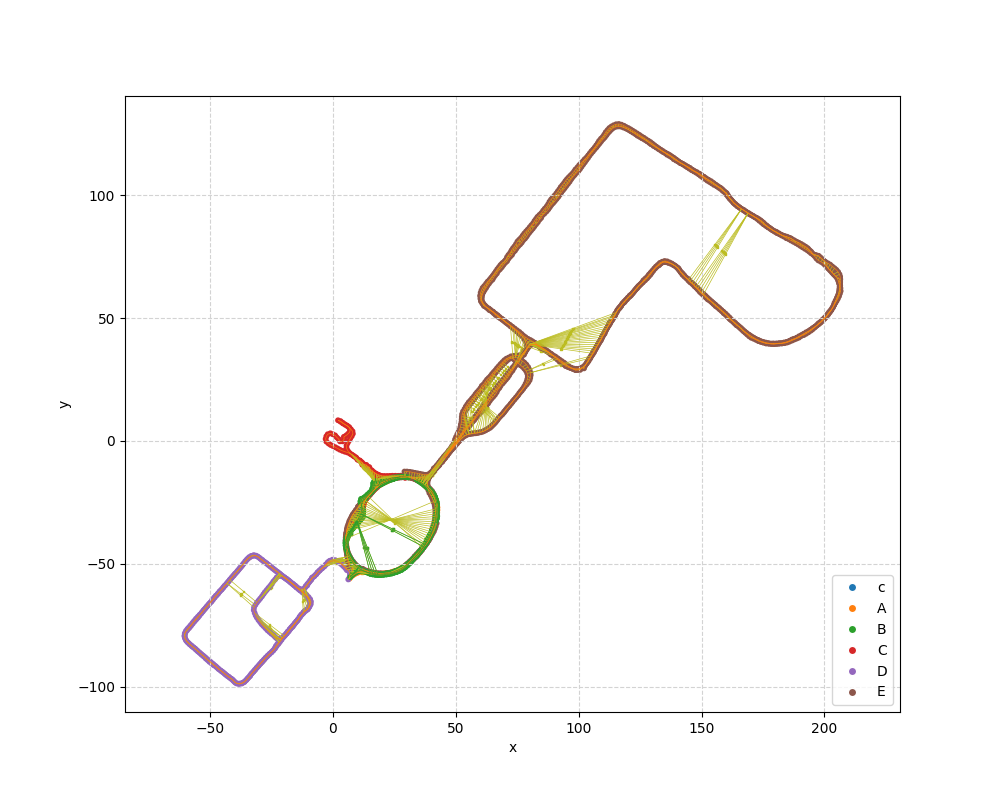

In [11]:
ax = fgtools.plot_graph(graph, values, changeColorBySymbols=True, symbolColors={ord('c'): "C0", ord('A'): "C1", ord('B'): "C2"})
mappingGraph, mappingValues = fgtools.createSubGraph(graph, values, session.sessionKeys['B'])
fgtools.plot_graph(mappingGraph, mappingValues, ax=ax, color_override="tab:green", alpha=1.0)
localizationGraph, localizationValues = fgtools.createSubGraph(graph, values, session.sessionKeys['c'])
fgtools.plot_graph(localizationGraph, localizationValues, ax=ax, color_override="tab:blue", alpha=1.0)
boundaryGraph, boundaryValues = fgtools.createSubGraph(graph, values, boundaryKeyRange)
fgtools.plot_graph(boundaryGraph, boundaryValues, ax=ax, color_override="tab:red", alpha=1.0)

In [12]:
import importlib
import opening_figure_3d as of3d
importlib.reload(of3d)

groups = of3d.group_keys_from_session(session, boundaryKeyRange)
colored_clouds = of3d.build_colored_clouds(session.scans, values, groups, voxel_size=0.2)

Prior: 230 scans -> 438147 points
Localization: 0 scans -> 0 points
Decision Region: 0 scans -> 0 points
Mapping: 186 scans -> 461881 points


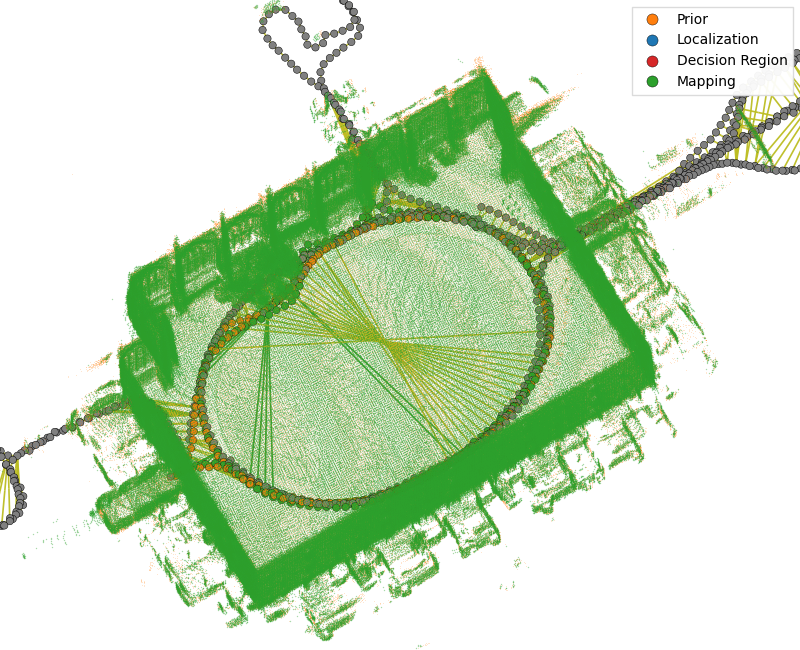

In [ ]:
fig, ax = of3d.plot_opening_figure_3d(graph, values, colored_clouds, groups, localization_z_offset=0.5)
# Rotate the widget to compose the view, or set it explicitly:
ax.view_init(elev=70, azim=-70)
# ax.get_legend().remove()
# fig.savefig("/home/benb/Pictures/ICRA_2027/opening_figure_3d.png", dpi=300, bbox_inches="tight", pad_inches=0.05, facecolor="white")

In [34]:
import importlib
import opening_figure_3d as of3d
importlib.reload(of3d)

# Legend-only figure, cropped to the legend box. Order comes from of3d.LEGEND_ORDER.
of3d.save_opening_legend("/home/benb/Pictures/ICRA_2027/opening_figure_legend.png")
# Horizontal layout:
# of3d.save_opening_legend("/home/benb/Pictures/ICRA_2027/opening_figure_legend.pdf", ncol=4)

Legend order: ['Prior', 'Localization', 'Decision Region', 'Mapping']
Saved legend /home/benb/Pictures/ICRA_2027/opening_figure_legend.png


PosixPath('/home/benb/Pictures/ICRA_2027/opening_figure_legend.png')